In [7]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from scipy import stats

In [8]:
X_train = pd.read_csv('../data/X_train.csv',index_col='ROW_ID')

y_train = pd.read_csv('../data/y_train.csv',index_col='ROW_ID')
total_data = pd.concat([X_train,y_train],axis=1)
print(total_data['target'])

ROW_ID
0         0.009210
1         0.000405
2         0.005967
3        -0.000542
4        -0.002579
            ...   
527068   -0.001769
527069    0.005640
527070    0.004016
527071    0.001617
527072    0.000556
Name: target, Length: 527073, dtype: float64


In [11]:
class ExactHMMFilter:
    def __init__(self, p_stay=0.8, mu_bull=1.0, mu_bear=-1.0, sigma=1.0):
        """
        Analytical HMM for a 2-state system (0 = Bear, 1 = Bull).
        Assumes symmetric transition probabilities.
        """
        # Transition Matrix: rows = from state, cols = to state
        self.A = np.array([
            [p_stay, 1.0 - p_stay],       # From Bear: [Stay Bear, Go Bull]
            [1.0 - p_stay, p_stay]        # From Bull: [Go Bear, Stay Bull]
        ])
        
        self.means = np.array([mu_bear, mu_bull])
        self.sigma = sigma
        
    def forward_filter(self, sequence):
        """
        Computes the forward filtering probability P(State_t = Bull | observations up to t)
        for each step in a continuous row.
        """
        T = len(sequence)
        posteriors = np.zeros((T, 2))
        
        # Day 0 Prior: Uniform 50/50 starting assumption
        prior = np.array([0.5, 0.5])
        
        for t in range(T):
            # 1. Likelihood evaluation under Gaussian emission noise
            likelihood = stats.norm.pdf(sequence[t], loc=self.means, scale=self.sigma)
            
            # 2. Bayesian state update
            raw_posterior = prior * likelihood
            norm_factor = np.sum(raw_posterior) + 1e-12
            posterior = raw_posterior / norm_factor
            posteriors[t] = posterior
            
            # 3. Predict next step prior distribution via transition matrix
            prior = posterior @ self.A
            
        return posteriors[:, 1] # Return probability stream for state 1 (Bull)

    def viterbi_decode(self, sequence):
        """
        Computes the single most likely path of hidden states (Viterbi Path) 
        across the 20-step window.
        """
        T = len(sequence)
        viterbi = np.zeros((T, 2))
        backpointer = np.zeros((T, 2), dtype=int)
        
        # Initialization using index 0 explicitly
        viterbi[0] = np.log([0.5, 0.5]) + np.log(stats.norm.pdf(sequence[0], loc=self.means, scale=self.sigma) + 1e-12)
        
        # Forward Viterbi recursion
        for t in range(1, T):
            for s in [0, 1]:  # FIXED: Explicitly loop through states (0=Bear, 1=Bull)
                log_emission = np.log(stats.norm.pdf(sequence[t], loc=self.means[s], scale=self.sigma) + 1e-12)
                log_transitions = viterbi[t-1] + np.log(self.A[:, s])
                
                backpointer[t, s] = np.argmax(log_transitions)
                viterbi[t, s] = np.max(log_transitions) + log_emission
                
        # Backtracking path reconstruction
        path = np.zeros(T, dtype=int)
        path[T-1] = np.argmax(viterbi[T-1])
        for t in range(T-2, -1, -1):
            path[t] = backpointer[t+1, path[t+1]]
            
        return path

In [12]:
# Initialize the mathematical filter
# Scale mu to match the order of magnitude of your raw returns data variance
hmm = ExactHMMFilter(p_stay=0.8, mu_bull=0.01, mu_bear=-0.01, sigma=0.02)

# Extract columns in chronological sequence (from past to most recent)
# Note: check challenge details to see if RET_20 is the oldest or newest.
# Assuming RET_20 is the oldest day and RET_1 is yesterday:
chronological_ret_cols = [f'RET_{i}' for i in range(20, 0, -1)]

# Select a row to inspect (e.g., Row 42)
sample_row_id = X_train.index[42]
sample_sequence = X_train.loc[sample_row_id, chronological_ret_cols].values

# Run the analytical engines
bull_probabilities = hmm.forward_filter(sample_sequence)
most_likely_path = hmm.viterbi_decode(sample_sequence)

# Print structural overview
summary_df = pd.DataFrame({
    'Step (T-20 to T-1)': np.arange(1, 21),
    'Observed Return': sample_sequence,
    'Bull Probability': bull_probabilities,
    'Decoded Hidden State (0=Bear, 1=Bull)': most_likely_path
})
print(f"--- Analytical Hidden State Estimation for Row_ID: {sample_row_id} ---")
print(summary_df)


--- Analytical Hidden State Estimation for Row_ID: 42 ---
    Step (T-20 to T-1)  Observed Return  Bull Probability  \
0                    1        -0.011979          0.354584   
1                    2        -0.006048          0.341864   
2                    3        -0.001236          0.390318   
3                    4         0.005318          0.500286   
4                    5         0.002653          0.533284   
5                    6        -0.001689          0.498871   
6                    7        -0.004240          0.446524   
7                    8         0.001089          0.481488   
8                    9         0.002730          0.522998   
9                   10        -0.000554          0.506874   
10                  11        -0.004884          0.443324   
11                  12         0.004811          0.526062   
12                  13         0.000446          0.521200   
13                  14        -0.004808          0.452765   
14                  15     

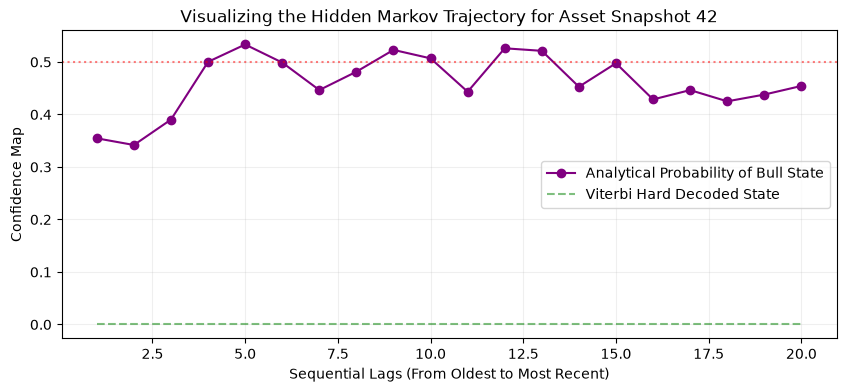

In [13]:

plt.figure(figsize=(10, 4))
plt.plot(range(1, 21), bull_probabilities, label='Analytical Probability of Bull State', color='purple', marker='o')
plt.step(range(1, 21), most_likely_path, label='Viterbi Hard Decoded State', where='mid', color='green', alpha=0.5, linestyle='--')
plt.axhline(0.5, color='red', linestyle=':', alpha=0.5)
plt.title(f'Visualizing the Hidden Markov Trajectory for Asset Snapshot {sample_row_id}')
plt.xlabel('Sequential Lags (From Oldest to Most Recent)')
plt.ylabel('Confidence Map')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()
